# 03. 自作のエクスポージャー

エクスポージャーは「(ym, ymd) → 表（bid + ファクター列）」を返す関数です。次の 2 つの作り方があります。

- (a) **月ごとの関数**：`ym` → 月末の表 を書いて `factors.monthly(...)` で包む
- (b) **パネル形式の表**：全月分を `ym` 列付きの 1 つの表にして `factors.panel(...)` に渡す

標準化（デフォルトは Blom スコア）と欠損の扱いはエンジン側で行うので、生の値を返して構いません。

In [1]:
import pandas as pd

from p_ken import charts, factors, io
from p_ken.stats import annualized

START, END = "2026-01-01", "2026-09-30"  # 計算期間（年初来）
Q_START = "2026-07-01"  # 強調する四半期の初日
HIGHLIGHT = (Q_START, END)


def pct(x):
    """表示用：小数のリターンを +1.23% 形式の文字列に。"""
    return x.map("{:+.2%}".format)


from p_ken.stats import blom

## 1. (a) 月ごとの関数

AI 70% / Revision 30% の合成と、中国銘柄だけの QIP（特許の発明件数）を作ります。
QIP は中国以外が欠損になり、その日の回帰では欠損の銘柄を除きます。

In [2]:
def my_exposures(ym: str) -> pd.DataFrame:
    ai = io.load_ai(ym).drop_duplicates("bid").set_index("bid")
    rev = io.load_revision(ym).drop_duplicates("bid").set_index("bid")
    df = ai.join(rev, how="outer").fillna(0.0)
    df["ai70_rev30"] = blom(0.7 * df.ai + 0.3 * df.rev)
    qip = io.load_qip(ym).set_index("bid")
    df = df.join(qip.loc[qip.ctry == "CN", "invention_count_12m"].rename("qip"))
    return df[["ai70_rev30", "qip"]].reset_index()


ex = my_exposures("202606")
ex.describe().round(3)  # 2026/06 末の分布（count = 値のある銘柄数）

,ai70_rev30,qip
count,1176.000,576.000
mean,-0.000,522.924
std,0.999,1298.128
min,-3.273,0.000
25%,-0.674,13.750
50%,0.000,79.000
75%,0.674,327.750
max,3.273,8460.000


## 2. 回帰（デフォルト）

In [3]:
src = factors.monthly(my_exposures)
reg = factors.regression_returns("gemq", src, START, END)
annualized(reg).round(4)

,start,end,days,total,ann_ret,ann_risk,hit,rr
ai70_rev30,2026-01-01,2026-09-30,195,0.0859,0.1111,0.0358,0.6410,3.0982
qip,2026-01-01,2026-09-30,195,0.0291,0.0376,0.0353,0.5077,1.0648


### 標準化の方法を変える

`standardize=` で `"blom"`（デフォルト）/ `"zscore"` / `"raw"`（そのまま）を選べます。
`raw` のときの傾きは「生の値 1 単位あたり」のリターンなので、大きさは比較できません。

In [4]:
pd.DataFrame(
    {
        s: factors.regression_returns("gemq", src, START, END, standardize=s).loc[Q_START:].sum()
        for s in ["blom", "zscore", "raw"]
    }
).map("{:+.4%}".format)

,blom,zscore,raw
ai70_rev30,-0.9583%,-0.9570%,-0.9583%
qip,-1.3010%,+1.7411%,+0.0014%


## 3. 分位版

`quantile_returns` は分位ポートフォリオの超過リターン（その日の全銘柄平均との差）です。

- `q=10`：10 分位
- `group=None`：最上位（D10）、`group=1`：最下位、`group="spread"`：最上位 − 最下位

In [5]:
q10 = factors.quantile_returns("gemq", src, START, END, q=10)
d1 = factors.quantile_returns("gemq", src, START, END, q=10, group=1)
spread = factors.quantile_returns("gemq", src, START, END, q=10, group="spread")
pct(
    pd.DataFrame(
        {
            "D10": q10.loc[Q_START:].sum(),
            "D1": d1.loc[Q_START:].sum(),
            "D10 - D1": spread.loc[Q_START:].sum(),
            "regression": reg.loc[Q_START:].sum(),
        }
    )
)

,D10,D1,D10 - D1,regression
ai70_rev30,-7.68%,-1.33%,-6.35%,-0.96%
qip,+5.27%,-1.65%,+6.92%,-1.30%


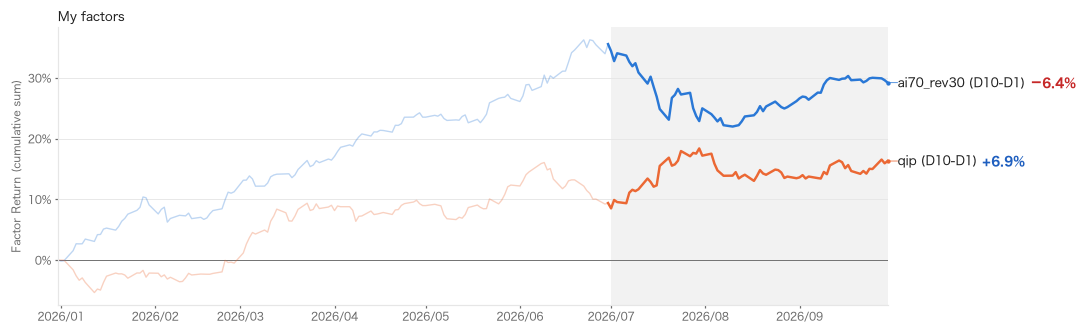

In [6]:
fig = charts.plot_cumulative(
    spread.add_suffix(" (D10-D1)"), START, HIGHLIGHT, "My factors", dpi=110
)

## 4. (b) パネル形式の表

自分で作った CSV などを読み込む場合は、`ym` 列付きの 1 つの表にして `factors.panel` に渡します。
ここでは AI スコアを全月分つなげた表を使います（結果はデフォルトの AI と同じになります）。

In [7]:
panel = pd.concat(
    [
        io.load_ai(ym).assign(ym=ym)
        for ym in io.list_yms("gemq", "exposures/nam/ai")
        if ym >= "202512"
    ],
    ignore_index=True,
)
print(panel.shape, list(panel.columns))

ai_panel = factors.regression_returns("gemq", factors.panel(panel), START, END)["ai"]
ai_default = factors.nam_factor_returns("gemq", START, END)["AI"]
print(
    "Jul-Sep:",
    f"panel {ai_panel.loc[Q_START:].sum():+.4%}",
    f"/ default {ai_default.loc[Q_START:].sum():+.4%}",
)

(11111, 3) ['bid', 'ai', 'ym']


Jul-Sep: panel -1.6524% / default -1.6524%
